# Семинар 10
# Сверточные нейронные сети. Сегментация и детекция
# Курс "Компьютерное зрение"

# 1. Перенос обучения и использование предобученных CNN-моделей
На практике очень немногие обучают всю сверточную сеть с нуля (со случайной инициализацией), потому что набор данных достаточного размера встречается относительно редко. Вместо этого обычно предварительно обучают ConvNet на очень большом наборе данных (например, ImageNet, который содержит 1,2 миллиона изображений с 1000 категориями), а затем используют ConvNet либо в качестве инициализации, либо в качестве feature extractor для интересующей задачи.

Эти два основных сценария трансферного обучения выглядят следующим образом:

* **Finetuning the convnet:** вместо случайной инициализации мы инициализируем сеть предварительно обученной сетью, подобной той, которая обучена на наборе данных imagenet 1000. В остальном тренировка проходит как обычно.

* __ConvNet as fixed feature extractor__: здесь мы заморозим веса для всей сети, кроме веса последнего полносвязного слоя. Этот последний полносвязный слой заменяется новым со случайными весами, и обучается только этот слой.

In [ ]:
from __future__ import print_function, division

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import copy

plt.ion()   # interactive mode

In [ ]:
# Add access to Google Colab
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)

Mounted at /content/gdrive


In [ ]:
%cd /content/gdrive/My\ Drive/Семинар10

/content/gdrive/My Drive/Семинар10


## 1.1. Загрузка данных

Задача — обучить модель классифицировать муравьев и пчел. У нас есть около 120 обучающих изображений для муравьев и пчел. Для каждого класса есть 75 тестовых изображений. Считается, что это очень небольшой набор данных для обучения, если обучение проводится с нуля. Поскольку мы используем transfer learning, у нас должна получится неплохая точность.

Этот набор данных является очень небольшим подмножеством imagenet.

In [ ]:
!wget https://download.pytorch.org/tutorial/hymenoptera_data.zip
!unzip hymenoptera_data.zip

--2022-04-19 13:50:38--  https://download.pytorch.org/tutorial/hymenoptera_data.zip
Resolving download.pytorch.org (download.pytorch.org)... 52.84.18.100, 52.84.18.116, 52.84.18.109, ...
Connecting to download.pytorch.org (download.pytorch.org)|52.84.18.100|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47286322 (45M) [application/zip]
Saving to: ‘hymenoptera_data.zip’

hymenoptera_data.zi 100%[===================>]  45.10M  34.6MB/s    in 1.3s    

2022-04-19 13:50:40 (34.6 MB/s) - ‘hymenoptera_data.zip’ saved [47286322/47286322]

Archive:  hymenoptera_data.zip
   creating: hymenoptera_data/
   creating: hymenoptera_data/train/
   creating: hymenoptera_data/train/ants/
  inflating: hymenoptera_data/train/ants/0013035.jpg  
  inflating: hymenoptera_data/train/ants/1030023514_aad5c608f9.jpg  
  inflating: hymenoptera_data/train/ants/1095476100_3906d8afde.jpg  
  inflating: hymenoptera_data/train/ants/1099452230_d1949d3250.jpg  
  inflating: hymenoptera_data/tr

In [ ]:
# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([ #Составляет несколько преобразований вместе
        transforms.RandomResizedCrop(224), # Обрезает случайную часть изображения и изменяет ее размер до заданного размера
        transforms.RandomHorizontalFlip(), #Переворачивает заданное изображение по горизонтали случайным образом с заданной вероятностью
        transforms.ToTensor(), #Преобразует изображение PIL или numpy.ndarray в тензор
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]) #Нормализует изображение тензора
    ]),
    'val': transforms.Compose([
        transforms.Resize(256), #Изменяет размер входного изображения до заданного размера
        transforms.CenterCrop(224), #Обрезает данное изображение по центру
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

In [ ]:
data_dir = 'hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:481: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


## 1.2. Визуализируем несколько изображений

In [ ]:
def imshow(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.subplots(figsize=(10,10))
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated

/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:477: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


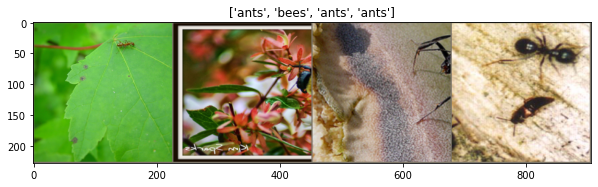

In [ ]:
# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs) #возвращает тензор, который содержит сетку изображений

imshow(out, title=[class_names[x] for x in classes])

## 1.3. Функция для обучения модели

Теперь давайте напишем общую функцию для обучения модели. Здесь мы проиллюстрируем:

- Планирование скорости обучения
- Сохранение лучшей модели

В дальнейшем планировщик параметров представляет собой объект планировщика LR из torch.optim.lr_scheduler.

In [ ]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs - 1))
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                # track history if only in train
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step() # обновление

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
            

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print('{} Loss: {:.4f} Acc: {:.4f}'.format(
                phase, epoch_loss, epoch_acc))


            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()


    time_elapsed = time.time() - since
    print('Training complete in {:.0f}m {:.0f}s'.format(
        time_elapsed // 60, time_elapsed % 60))
    print('Best val Acc: {:4f}'.format(best_acc))

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model

## 1.4. Функция для визуализации откликов модели

In [ ]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title('predicted: {}'.format(class_names[preds[j]]))
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

## 1.5. Перенос обучения и finetuning модели

In [ ]:
model_ft = models.resnet18(pretrained=True)
num_ftrs = model_ft.fc.in_features


# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to nn.Linear(num_ftrs, len(class_names)).
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-5c106cde.pth" to /root/.cache/torch/hub/checkpoints/resnet18-5c106cde.pth


In [ ]:
criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Затухание LR на коэффициент 0,1 каждые 7 эпох
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

In [ ]:
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)

Epoch 0/24
----------


/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:477: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


train Loss: 0.6049 Acc: 0.7090
val Loss: 0.2528 Acc: 0.8954

Epoch 1/24
----------
train Loss: 0.4524 Acc: 0.8197
val Loss: 0.3462 Acc: 0.8562

Epoch 2/24
----------
train Loss: 0.4883 Acc: 0.7992
val Loss: 0.2143 Acc: 0.9281

Epoch 3/24
----------
train Loss: 0.5773 Acc: 0.7418
val Loss: 0.2468 Acc: 0.9085

Epoch 4/24
----------
train Loss: 0.4208 Acc: 0.8525
val Loss: 0.4812 Acc: 0.8366

Epoch 5/24
----------
train Loss: 0.4149 Acc: 0.8402
val Loss: 0.2846 Acc: 0.9150

Epoch 6/24
----------
train Loss: 0.5589 Acc: 0.8074
val Loss: 0.3758 Acc: 0.8889

Epoch 7/24
----------
train Loss: 0.4466 Acc: 0.8648
val Loss: 0.3631 Acc: 0.8954

Epoch 8/24
----------
train Loss: 0.2982 Acc: 0.8689
val Loss: 0.2775 Acc: 0.9085

Epoch 9/24
----------
train Loss: 0.3413 Acc: 0.8730
val Loss: 0.3080 Acc: 0.8954

Epoch 10/24
----------
train Loss: 0.3533 Acc: 0.8566
val Loss: 0.2557 Acc: 0.9150

Epoch 11/24
----------
train Loss: 0.3380 Acc: 0.8607
val Loss: 0.2462 Acc: 0.9150

Epoch 12/24
----------
t

Визуализируем результат обучения

/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:477: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


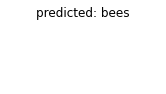

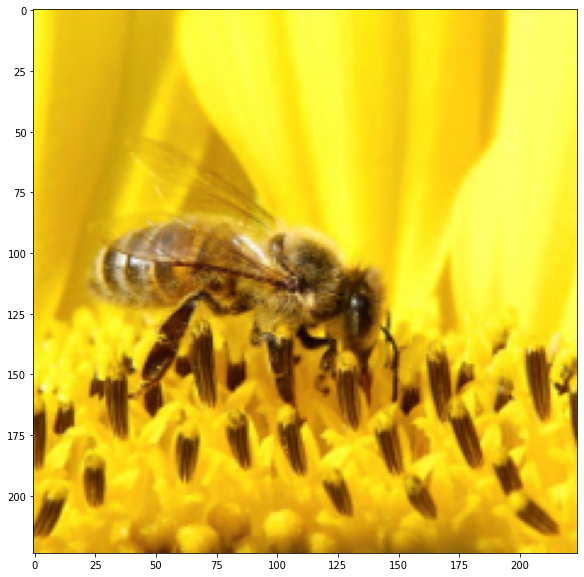

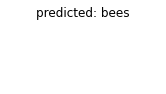

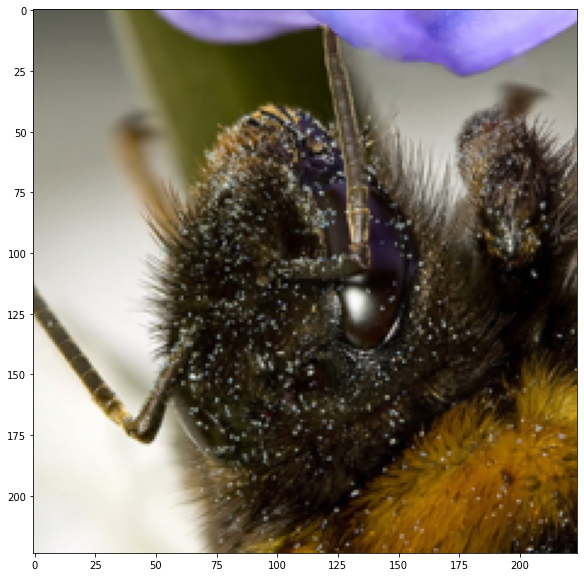

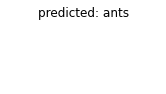

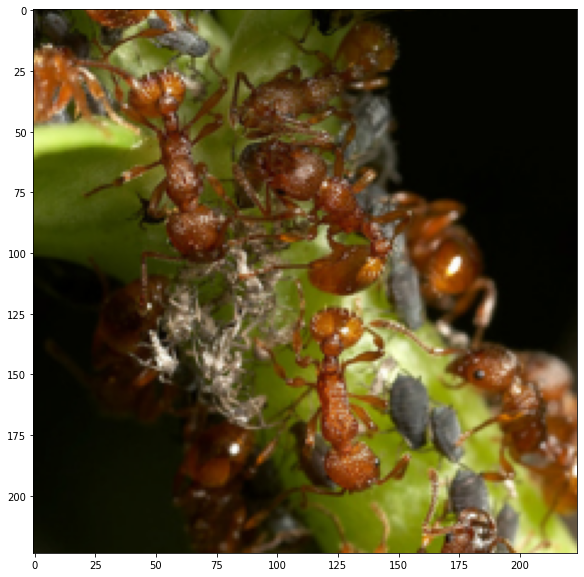

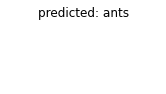

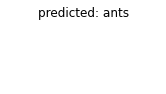

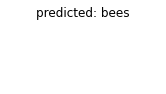

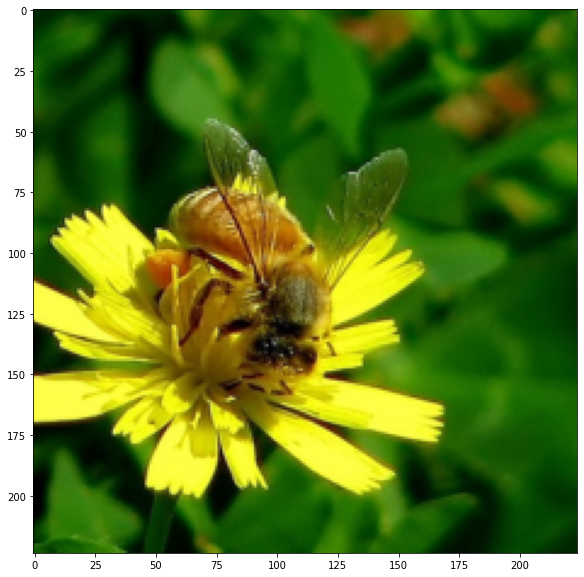

In [ ]:
visualize_model(model_ft)

## 1.6 ConvNet как fixed feature extractor

Здесь нам нужно заморозить всю сеть, кроме последнего слоя. Нам нужно установить require_grad = False, чтобы заморозить параметры, чтобы градиенты не вычислялись в reverse().

Подробнее об этом можно прочитать в документации https://pytorch.org/docs/master/notes/autograd.html

In [ ]:
model_conv = torchvision.models.resnet18(pretrained=True)
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as
# opposed to before.
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

In [ ]:
model_conv = train_model(model_conv, criterion, optimizer_conv,
                         exp_lr_scheduler, num_epochs=25)

Epoch 0/24
----------


/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:481: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


train Loss: 0.6052 Acc: 0.6926
val Loss: 0.2749 Acc: 0.8954

Epoch 1/24
----------
train Loss: 0.4809 Acc: 0.7787
val Loss: 0.2099 Acc: 0.9412

Epoch 2/24
----------
train Loss: 0.4082 Acc: 0.8320
val Loss: 0.1712 Acc: 0.9542

Epoch 3/24
----------
train Loss: 0.5207 Acc: 0.7828
val Loss: 0.2094 Acc: 0.9412

Epoch 4/24
----------
train Loss: 0.4455 Acc: 0.8033
val Loss: 0.2319 Acc: 0.9346

Epoch 5/24
----------
train Loss: 0.5582 Acc: 0.7664
val Loss: 0.2363 Acc: 0.9150

Epoch 6/24
----------
train Loss: 0.3955 Acc: 0.8238
val Loss: 0.2836 Acc: 0.8954

Epoch 7/24
----------
train Loss: 0.4077 Acc: 0.8115
val Loss: 0.1781 Acc: 0.9477

Epoch 8/24
----------
train Loss: 0.3382 Acc: 0.8566
val Loss: 0.2454 Acc: 0.9216

Epoch 9/24
----------
train Loss: 0.3399 Acc: 0.8361
val Loss: 0.1736 Acc: 0.9412

Epoch 10/24
----------
train Loss: 0.2323 Acc: 0.9221
val Loss: 0.1691 Acc: 0.9542

Epoch 11/24
----------
train Loss: 0.3558 Acc: 0.8361
val Loss: 0.1729 Acc: 0.9412

Epoch 12/24
----------
t

In [ ]:
visualize_model(model_conv)

plt.ioff()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

На CPU это займет примерно половину времени по сравнению с предыдущим сценарием. Это ожидаемо, поскольку градиенты не нужно вычислять для большей части сети. Тем не менее, forward должен быть рассчитан.

# 2. Семантическая сегментация на основе U-Net

Мы хотели бы иметь генератор данных, который делает следующее:

 - Он выбирает пары input-target
 - Он выполняет некоторые преобразования данных «на лету».

In [ ]:
import torch
from skimage.io import imread
from torch.utils import data
from tqdm.notebook import tqdm, trange

import numpy as np
from skimage.transform import resize
from sklearn.externals._pilutil import bytescale

from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import os
import albumentations

from torch import nn
import pandas as pd
from matplotlib import pyplot as plt
import math

## 2.1. Создадим класс датасета

In [ ]:
class SegmentationDataSetFullRes(data.Dataset):
    def __init__(self,
                 inputs: list,
                 targets: list,
                 transform=None
                 ):
        self.inputs = inputs
        self.targets = targets
        self.transform = transform
        self.inputs_dtype = torch.float32
        self.targets_dtype = torch.long

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self,
                    index: int):
        # Select the sample
        input_ID = self.inputs[index]
        target_ID = self.targets[index]

        # Load input and target
        x, y = imread("Carvana/Input/"+input_ID), imread("Carvana/Target/"+target_ID)

        # Preprocessing
        if self.transform is not None:
            x, y = self.transform(x, y)

        # Typecasting
        x, y = torch.from_numpy(x).type(self.inputs_dtype), torch.from_numpy(y).type(self.targets_dtype)

        return x, y




class SegmentationDataSet(data.Dataset):
    def __init__(self,
                 inputs: list,
                 targets: list,
                 transform=None,
                 use_cache=False,
                 pre_transform=None,
                 ):
        self.inputs = inputs
        self.targets = targets
        self.transform = transform
        self.inputs_dtype = torch.float32
        self.targets_dtype = torch.long
        self.use_cache = use_cache
        self.pre_transform = pre_transform

        if self.use_cache:
            from multiprocessing import Pool
            from itertools import repeat

            with Pool() as pool:
                self.cached_data = pool.starmap(self.read_images, zip(inputs, targets, repeat(self.pre_transform)))

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self,
                    index: int):
        if self.use_cache:
            x, y = self.cached_data[index]
        else:
            # Select the sample
            input_ID = self.inputs[index]
            target_ID = self.targets[index]

            # Load input and target
            x, y = imread("Carvana/Input/"+input_ID), imread("Carvana/Target/"+target_ID)

        # Preprocessing
        if self.transform is not None:
            x, y = self.transform(x, y)

        # Typecasting
        x, y = torch.from_numpy(x).type(self.inputs_dtype), torch.from_numpy(y).type(self.targets_dtype)

        return x, y

    @staticmethod
    def read_images(inp, tar, pre_transform):
        inp, tar = imread(inp), imread(tar)
        if pre_transform:
            inp, tar = pre_transform(inp, tar)
        return inp, tar

## 2.2. Добавим аугментации

In [ ]:
def create_dense_target(tar: np.ndarray):
    classes = np.unique(tar)
    dummy = np.zeros_like(tar)
    for idx, value in enumerate(classes):
        mask = np.where(tar == value)
        dummy[mask] = idx

    return dummy


def normalize_01(inp: np.ndarray):
    """Ввод изображения в диапазоне значений [0, 1] (без обрезки)"""
    inp_out = (inp - np.min(inp)) / np.ptp(inp)
    return inp_out


def normalize(inp: np.ndarray, mean: float, std: float):
    """Нормировать на основе среднего и стандартного отклонения."""
    inp_out = (inp - mean) / std
    return inp_out


def re_normalize(inp: np.ndarray,
                 low: int = 0,
                 high: int = 255
                 ):
    """Нормализация данных до определенного диапазона. По умолчанию: [0-255]"""
    inp_out = bytescale(inp, low=low, high=high)
    return inp_out


class Compose:
    """
    Composes several transforms together.
    """

    def __init__(self, transforms: list):
        self.transforms = transforms

    def __call__(self, inp, target):
        for t in self.transforms:
            inp, target = t(inp, target)
        return inp, target

    def __repr__(self): return str([transform for transform in self.transforms])


class MoveAxis:
    """From [H, W, C] to [C, H, W]"""

    def __init__(self, transform_input: bool = True, transform_target: bool = False):
        self.transform_input = transform_input
        self.transform_target = transform_target

    def __call__(self, inp: np.ndarray, tar: np.ndarray):
        if self.transform_input: inp = np.moveaxis(inp, -1, 0)
        if self.transform_target: tar = np.moveaxis(inp, -1, 0)

        return inp, tar

    def __repr__(self):
        return str({self.__class__.__name__: self.__dict__})


class DenseTarget:
    """Создает карты сегментации с последовательными целыми числами, начиная с 0"""

    def __init__(self):
        pass

    def __call__(self, inp: np.ndarray, tar: np.ndarray):
        tar = create_dense_target(tar)

        return inp, tar

    def __repr__(self):
        return str({self.__class__.__name__: self.__dict__})


class Resize:
    """Изменяет размеры изображения и target - based на основе изображения"""

    def __init__(self,
                 input_size: tuple,
                 target_size: tuple,
                 input_kwargs: dict = {},
                 target_kwargs: dict = {'order': 0, 'anti_aliasing': False, 'preserve_range': True}
                 ):
        self.input_size = input_size
        self.target_size = target_size
        self.input_kwargs = input_kwargs
        self.target_kwargs = target_kwargs

    def __call__(self, inp: np.ndarray, tar: np.ndarray):
        self.input_dtype = inp.dtype
        self.target_dtype = tar.dtype

        inp_out = resize(image=inp,
                         output_shape=self.input_size,
                         **self.input_kwargs
                         )
        tar_out = resize(image=tar,
                         output_shape=self.target_size,
                         **self.target_kwargs
                         ).astype(self.target_dtype)
        return inp_out, tar_out

    def __repr__(self):
        return str({self.__class__.__name__: self.__dict__})


class Normalize01:
    """Ввод изображения в диапазоне значений [0, 1] (без обрезки)"""

    def __init__(self):
        pass

    def __call__(self, inp, tar):
        inp = normalize_01(inp)

        return inp, tar

    def __repr__(self):
        return str({self.__class__.__name__: self.__dict__})


class Normalize:
    """Нормировать на основе среднего и стандартного отклонения."""

    def __init__(self,
                 mean: float,
                 std: float,
                 transform_input=True,
                 transform_target=False
                 ):
        self.transform_input = transform_input
        self.transform_target = transform_target
        self.mean = mean
        self.std = std

    def __call__(self, inp, tar):
        inp = normalize(inp)

        return inp, tar

    def __repr__(self):
        return str({self.__class__.__name__: self.__dict__})


class AlbuSeg2d:
    """Обертка для 2D-аугментаций
     Обертывает расширение, чтобы его можно было использовать в предоставленном конвейере преобразования.
     Ожидаемый ввод: (C, space_dims)
     Ожидаемая цель: (spatial_dims) -> Без измерения канала (C)
     """
    def __init__(self, albu):
        self.albu = albu

    def __call__(self, inp, tar):
        # input, target
        out_dict = self.albu(image=inp, mask=tar)
        input_out = out_dict['image']
        target_out = out_dict['mask']

        return input_out, target_out

    def __repr__(self):
        return str({self.__class__.__name__: self.__dict__})

При желании можно написать дополнительную обертку для использования специализированной библиотеки аугментации Albumentations

## 2.3. Создадим Dataloader
Carvana dataset consists of only 6 cars, but each car from 16 angles — 96 images in total. 

In [ ]:
# root directory
root = 'Carvana'

In [ ]:
def get_filenames_of_path(path):
    """Returns a list of files in a directory/path. Uses pathlib."""
    filenames = [filename for filename in os.listdir(path)]
    return filenames

# input and target files
inputs = sorted(get_filenames_of_path(root+'/Input'))
targets = sorted(get_filenames_of_path(root+'/Target'))

In [ ]:
# pre-transformations
pre_transforms = Compose([
    Resize(input_size=(128, 128, 3), target_size=(128, 128)),
])
# training transformations and augmentations
transforms_training = Compose([
    Resize(input_size=(128, 128, 3), target_size=(128, 128)),
    AlbuSeg2d(albu=albumentations.HorizontalFlip(p=0.5)),
    DenseTarget(),
    MoveAxis(),
    Normalize01()
])
# validation transformations
transforms_validation = Compose([
    Resize(input_size=(128, 128, 3), target_size=(128, 128)),
    DenseTarget(),
    MoveAxis(),
    Normalize01()
])
# random seed
random_seed = 42
# split dataset into training set and validation set
train_size = 0.8  # 80:20 split



In [ ]:
inputs_train,inputs_valid, targets_train, targets_valid = train_test_split(
    inputs, targets,
    random_state=random_seed,
    train_size=train_size,
    shuffle=True)

# dataset training
dataset_train = SegmentationDataSet(inputs=inputs_train,
                                    targets=targets_train,
                                    transform=transforms_training)

# dataset validation
dataset_valid = SegmentationDataSet(inputs=inputs_valid,
                                    targets=targets_valid,
                                    transform=transforms_validation)

# dataloader training
dataloader_training = DataLoader(dataset=dataset_train,
                                 batch_size=2,
                                 shuffle=True)

# dataloader validation
dataloader_validation = DataLoader(dataset=dataset_valid,
                                   batch_size=2,
                                   shuffle=True)

## 2.4. Визуализируем загрузчик данных

Чтобы проверить результаты нашего загрузчика данных, мы должны визуализировать ввод и соответствующее целевое изображение. Для 2D-изображений мы могли бы использовать matplotlib. Однако для 3D-изображений это становится немного хакерским и медленным. Но есть альтернатива: napari. Это быстрый интерактивный просмотрщик многомерных изображений для Python, который можно использовать в блокноте Jupyter, консоли Ipython или в скрипте .py.

In [ ]:
def show_input_target_pair_napari(gen_training, gen_validation=None):
    """
    Press 't' to get a random sample of the next training batch.
    Press 'v' to get a random sample of the next validation batch.
    """
    # Batch
    x, y = next(iter(gen_training))
    plt.subplots(nrows=1, ncols=2, figsize=(10,10))
    plt.subplot(121), plt.imshow(x)
    plt.subplot(122), plt.imshow(y)


class Input_Target_Pair_Generator:
    def __init__(self,
                 dataloader,
                 re_normalize=True,
                 rgb=False,
                 ):
        self.dataloader = dataloader
        self.re_normalize = re_normalize
        self.rgb = rgb

    def __iter__(self):
        return self

    def __next__(self):
        x, y = next(iter(self.dataloader))
        x, y = x.cpu().numpy(), y.cpu().numpy()  # make sure it's a numpy.ndarray on the cpu

        # Batch
        batch_size = x.shape[0]
        rand_num = np.random.randint(low=0, high=batch_size)
        x, y = x[rand_num], y[rand_num]  # Pick a random image from the batch

        # RGB
        if self.rgb:
            x = np.moveaxis(x, source=0, destination=-1)  # from [C, H, W] to [H, W, C]

        # Re-normalize
        if self.re_normalize:
            x = re_normalize(x)

        return x, y

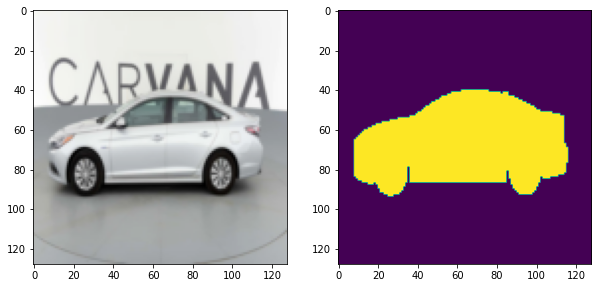

In [ ]:
gen = Input_Target_Pair_Generator(dataloader_training, rgb=True)
show_input_target_pair_napari(gen)

## 2.5. Добавление дополнительных аугментаций

Для 2D-изображений нам не нужно реализовывать все с нуля с помощью numpy. Вместо этого мы могли бы использовать библиотеку, например, альбументации. Для этого нам просто нужно написать обертку, например, AlbuSeg2d. Например, мы можем горизонтально отразить наши тренировочные изображения и их соответствующие targets. Validation изображения обычно не дополняются, что требует различных преобразований для набора данных для обучения и проверки.

In [ ]:
# training transformations and augmentations
transforms_training = Compose([
    Resize(input_size=(128, 128, 3), target_size=(128, 128)),
    AlbuSeg2d(albu=albumentations.HorizontalFlip(p=0.5)),
    DenseTarget(),
    MoveAxis(),
    Normalize01()
])

# validation transformations
transforms_validation = Compose([
    Resize(input_size=(128, 128, 3), target_size=(128, 128)),
    DenseTarget(),
    MoveAxis(),
    Normalize01()
])

Внесем изменения в инициализацию датасета

In [ ]:
# dataset training
dataset_train = SegmentationDataSet(inputs=inputs_train,
                                    targets=targets_train,
                                    transform=transforms_training)

# dataset validation
dataset_valid = SegmentationDataSet(inputs=inputs_valid,
                                    targets=targets_valid,
                                    transform=transforms_validation)

## 2.6. Создание модели U-Net

U-Net — это архитектура сверточной нейронной сети, предназначенная для быстрой и точной сегментации изображений. Он очень хорошо показал себя в нескольких задачах и по сей день является одной из самых популярных архитектур в области семантической сегментации.

<figure>
<img src="https://miro.medium.com/max/1050/1*hzufVrlQYVs_Lj-vHw8SgQ.png" width="1000">
</figure> 


- Кодер захватывает объекты в разных масштабах изображений, используя традиционный стек сверточных слоев и слоев максимального объединения. Конкретно говоря, блок в кодере состоит из многократного использования двух сверточных слоев (k = 3, s = 1), за каждым из которых следует слой нелинейности, и слой максимального объединения (k = 2, s = 2). ). Для каждого блока свертки и связанной с ним операции максимального объединения количество карт объектов удваивается, чтобы сеть могла эффективно изучать сложные структуры.

- Путь декодера представляет собой симметричный расширяющийся аналог, использующий транспонированные свертки. Этот тип сверточного слоя представляет собой метод повышающей дискретизации с обучаемыми параметрами и выполняет обратное (понижающее) объединение слоев, таких как максимальный пул. Подобно кодеру, за каждым блоком свертки следует такой слой свертки вверх. Количество карт признаков в каждом блоке уменьшается вдвое. Поскольку воссоздание маски сегментации из небольшой карты объектов является довольно сложной задачей для сети, выходные данные после каждого сверточного слоя дополняются картами объектов соответствующего блока кодировщика. Карты объектов слоя кодировщика обрезаются, если размеры превышают размеры соответствующих слоев декодера.

- В конце выходные данные проходят еще один слой свертки (k=1, s=1) с количеством карт объектов, равным количеству определенных меток. В результате получается U-образная сверточная сеть, которая предлагает элегантное решение для хорошей локализации и использования контекста.


In [ ]:
@torch.jit.script
def autocrop(encoder_layer: torch.Tensor, decoder_layer: torch.Tensor):
    """
    Обрезает encoder_layer по размеру decoder_layer,
     так что слияние (конкатенация) между уровнями/блоками возможно.
     Это необходимо только для входных размеров != 2**n 
     для 'same' padding и всегда требуется для 'valid' padding.
    """
    if encoder_layer.shape[2:] != decoder_layer.shape[2:]:
        ds = encoder_layer.shape[2:]
        es = decoder_layer.shape[2:]
        assert ds[0] >= es[0]
        assert ds[1] >= es[1]
        if encoder_layer.dim() == 4:  # 2D
            encoder_layer = encoder_layer[
                            :,
                            :,
                            ((ds[0] - es[0]) // 2):((ds[0] + es[0]) // 2),
                            ((ds[1] - es[1]) // 2):((ds[1] + es[1]) // 2)
                            ]
        elif encoder_layer.dim() == 5:  # 3D
            assert ds[2] >= es[2]
            encoder_layer = encoder_layer[
                            :,
                            :,
                            ((ds[0] - es[0]) // 2):((ds[0] + es[0]) // 2),
                            ((ds[1] - es[1]) // 2):((ds[1] + es[1]) // 2),
                            ((ds[2] - es[2]) // 2):((ds[2] + es[2]) // 2),
                            ]
    return encoder_layer, decoder_layer


def conv_layer(dim: int):
    if dim == 3:
        return nn.Conv3d
    elif dim == 2:
        return nn.Conv2d


def get_conv_layer(in_channels: int,
                   out_channels: int,
                   kernel_size: int = 3,
                   stride: int = 1,
                   padding: int = 1,
                   bias: bool = True,
                   dim: int = 2):
    return conv_layer(dim)(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding,
                           bias=bias)


def conv_transpose_layer(dim: int):
    if dim == 3:
        return nn.ConvTranspose3d
    elif dim == 2:
        return nn.ConvTranspose2d


def get_up_layer(in_channels: int,
                 out_channels: int,
                 kernel_size: int = 2,
                 stride: int = 2,
                 dim: int = 3,
                 up_mode: str = 'transposed',
                 ):
    if up_mode == 'transposed':
        return conv_transpose_layer(dim)(in_channels, out_channels, kernel_size=kernel_size, stride=stride)
    else:
        return nn.Upsample(scale_factor=2.0, mode=up_mode)


def maxpool_layer(dim: int):
    if dim == 3:
        return nn.MaxPool3d
    elif dim == 2:
        return nn.MaxPool2d


def get_maxpool_layer(kernel_size: int = 2,
                      stride: int = 2,
                      padding: int = 0,
                      dim: int = 2):
    return maxpool_layer(dim=dim)(kernel_size=kernel_size, stride=stride, padding=padding)


def get_activation(activation: str):
    if activation == 'relu':
        return nn.ReLU()
    elif activation == 'leaky':
        return nn.LeakyReLU(negative_slope=0.1)
    elif activation == 'elu':
        return nn.ELU()


def get_normalization(normalization: str,
                      num_channels: int,
                      dim: int):
    if normalization == 'batch':
        if dim == 3:
            return nn.BatchNorm3d(num_channels)
        elif dim == 2:
            return nn.BatchNorm2d(num_channels)
    elif normalization == 'instance':
        if dim == 3:
            return nn.InstanceNorm3d(num_channels)
        elif dim == 2:
            return nn.InstanceNorm2d(num_channels)
    elif 'group' in normalization:
        num_groups = int(normalization.partition('group')[-1])  # get the group size from string
        return nn.GroupNorm(num_groups=num_groups, num_channels=num_channels)

In [ ]:
class Concatenate(nn.Module):
    def __init__(self):
        super(Concatenate, self).__init__()

    def forward(self, layer_1, layer_2):
        x = torch.cat((layer_1, layer_2), 1)

        return x


class DownBlock(nn.Module):
    """
    Вспомогательный модуль, который выполняет 2 свертки и 1 MaxPool.
     После каждой свертки следует активация.
     После каждой свертки следует слой нормализации.
    """

    def __init__(self,
                 in_channels: int,
                 out_channels: int,
                 pooling: bool = True,
                 activation: str = 'relu',
                 normalization: str = None,
                 dim: str = 2,
                 conv_mode: str = 'same'):
        super().__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.pooling = pooling
        self.normalization = normalization
        if conv_mode == 'same':
            self.padding = 1
        elif conv_mode == 'valid':
            self.padding = 0
        self.dim = dim
        self.activation = activation

        # conv layers
        self.conv1 = get_conv_layer(self.in_channels, self.out_channels, kernel_size=3, stride=1, padding=self.padding,
                                    bias=True, dim=self.dim)
        self.conv2 = get_conv_layer(self.out_channels, self.out_channels, kernel_size=3, stride=1, padding=self.padding,
                                    bias=True, dim=self.dim)

        # pooling layer
        if self.pooling:
            self.pool = get_maxpool_layer(kernel_size=2, stride=2, padding=0, dim=self.dim)

        # activation layers
        self.act1 = get_activation(self.activation)
        self.act2 = get_activation(self.activation)

        # normalization layers
        if self.normalization:
            self.norm1 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)
            self.norm2 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)

    def forward(self, x):
        y = self.conv1(x)  # convolution 1
        y = self.act1(y)  # activation 1
        if self.normalization:
            y = self.norm1(y)  # normalization 1
        y = self.conv2(y)  # convolution 2
        y = self.act2(y)  # activation 2
        if self.normalization:
            y = self.norm2(y)  # normalization 2

        before_pooling = y  # save the outputs before the pooling operation
        if self.pooling:
            y = self.pool(y)  # pooling
        return y, before_pooling


class UpBlock(nn.Module):
    """
      Вспомогательный модуль, который выполняет 2 свертки и 1 UpConvolution/Upsample.
     После каждой свертки следует активация.
     После каждой свертки следует слой нормализации.
    """

    def __init__(self,
                 in_channels: int,
                 out_channels: int,
                 activation: str = 'relu',
                 normalization: str = None,
                 dim: int = 3,
                 conv_mode: str = 'same',
                 up_mode: str = 'transposed'
                 ):
        super().__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.normalization = normalization
        if conv_mode == 'same':
            self.padding = 1
        elif conv_mode == 'valid':
            self.padding = 0
        self.dim = dim
        self.activation = activation
        self.up_mode = up_mode

        # upconvolution/upsample layer
        self.up = get_up_layer(self.in_channels, self.out_channels, kernel_size=2, stride=2, dim=self.dim,
                               up_mode=self.up_mode)

        # conv layers
        self.conv0 = get_conv_layer(self.in_channels, self.out_channels, kernel_size=1, stride=1, padding=0,
                                    bias=True, dim=self.dim)
        self.conv1 = get_conv_layer(2 * self.out_channels, self.out_channels, kernel_size=3, stride=1,
                                    padding=self.padding,
                                    bias=True, dim=self.dim)
        self.conv2 = get_conv_layer(self.out_channels, self.out_channels, kernel_size=3, stride=1, padding=self.padding,
                                    bias=True, dim=self.dim)

        # activation layers
        self.act0 = get_activation(self.activation)
        self.act1 = get_activation(self.activation)
        self.act2 = get_activation(self.activation)

        # normalization layers
        if self.normalization:
            self.norm0 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)
            self.norm1 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)
            self.norm2 = get_normalization(normalization=self.normalization, num_channels=self.out_channels,
                                           dim=self.dim)

        # concatenate layer
        self.concat = Concatenate()

    def forward(self, encoder_layer, decoder_layer):
        """ Forward pass
         Аргументы:
             encoder_layer: тензор из пути кencoder pathway
             decoder_layer: тензор из decoder pathway (будет обновлен)
        """
        up_layer = self.up(decoder_layer)  # up-convolution/up-sampling
        cropped_encoder_layer, dec_layer = autocrop(encoder_layer, up_layer)  # cropping

        if self.up_mode != 'transposed':
            # We need to reduce the channel dimension with a conv layer
            up_layer = self.conv0(up_layer)  # convolution 0
        up_layer = self.act0(up_layer)  # activation 0
        if self.normalization:
            up_layer = self.norm0(up_layer)  # normalization 0

        merged_layer = self.concat(up_layer, cropped_encoder_layer)  # concatenation
        y = self.conv1(merged_layer)  # convolution 1
        y = self.act1(y)  # activation 1
        if self.normalization:
            y = self.norm1(y)  # normalization 1
        y = self.conv2(y)  # convolution 2
        y = self.act2(y)  # acivation 2
        if self.normalization:
            y = self.norm2(y)  # normalization 2
        return y

In [ ]:
class UNet(nn.Module):
    def __init__(self,
                 in_channels: int = 1,
                 out_channels: int = 2,
                 n_blocks: int = 4,
                 start_filters: int = 32,
                 activation: str = 'relu',
                 normalization: str = 'batch',
                 conv_mode: str = 'same',
                 dim: int = 2,
                 up_mode: str = 'transposed'
                 ):
        super().__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.n_blocks = n_blocks
        self.start_filters = start_filters
        self.activation = activation
        self.normalization = normalization
        self.conv_mode = conv_mode
        self.dim = dim
        self.up_mode = up_mode

        self.down_blocks = []
        self.up_blocks = []

        # create encoder path
        for i in range(self.n_blocks):
            num_filters_in = self.in_channels if i == 0 else num_filters_out
            num_filters_out = self.start_filters * (2 ** i)
            pooling = True if i < self.n_blocks - 1 else False

            down_block = DownBlock(in_channels=num_filters_in,
                                   out_channels=num_filters_out,
                                   pooling=pooling,
                                   activation=self.activation,
                                   normalization=self.normalization,
                                   conv_mode=self.conv_mode,
                                   dim=self.dim)

            self.down_blocks.append(down_block)

        # create decoder path (requires only n_blocks-1 blocks)
        for i in range(n_blocks - 1):
            num_filters_in = num_filters_out
            num_filters_out = num_filters_in // 2

            up_block = UpBlock(in_channels=num_filters_in,
                               out_channels=num_filters_out,
                               activation=self.activation,
                               normalization=self.normalization,
                               conv_mode=self.conv_mode,
                               dim=self.dim,
                               up_mode=self.up_mode)

            self.up_blocks.append(up_block)

        # final convolution
        self.conv_final = get_conv_layer(num_filters_out, self.out_channels, kernel_size=1, stride=1, padding=0,
                                         bias=True, dim=self.dim)

        # add the list of modules to current module
        self.down_blocks = nn.ModuleList(self.down_blocks)
        self.up_blocks = nn.ModuleList(self.up_blocks)

        # initialize the weights
        self.initialize_parameters()

    @staticmethod
    def weight_init(module, method, **kwargs):
        if isinstance(module, (nn.Conv3d, nn.Conv2d, nn.ConvTranspose3d, nn.ConvTranspose2d)):
            method(module.weight, **kwargs)  # weights

    @staticmethod
    def bias_init(module, method, **kwargs):
        if isinstance(module, (nn.Conv3d, nn.Conv2d, nn.ConvTranspose3d, nn.ConvTranspose2d)):
            method(module.bias, **kwargs)  # bias

    def initialize_parameters(self,
                              method_weights=nn.init.xavier_uniform_,
                              method_bias=nn.init.zeros_,
                              kwargs_weights={},
                              kwargs_bias={}
                              ):
        for module in self.modules():
            self.weight_init(module, method_weights, **kwargs_weights)  # initialize weights
            self.bias_init(module, method_bias, **kwargs_bias)  # initialize bias

    def forward(self, x: torch.tensor):
        encoder_output = []

        # Encoder pathway
        for module in self.down_blocks:
            x, before_pooling = module(x)
            encoder_output.append(before_pooling)

        # Decoder pathway
        for i, module in enumerate(self.up_blocks):
            before_pool = encoder_output[-(i + 2)]
            x = module(before_pool, x)

        x = self.conv_final(x)

        return x

    def __repr__(self):
        attributes = {attr_key: self.__dict__[attr_key] for attr_key in self.__dict__.keys() if '_' not in attr_key[0] and 'training' not in attr_key}
        d = {self.__class__.__name__: attributes}
        return f'{d}'

__Downsample block__
<figure>
<img src="https://miro.medium.com/max/1050/1*SsTwShoqsGjVCl4Ms7qpcw.png" width="1000">
</figure> 

__Upsample block__
<figure>
<img src="https://miro.medium.com/max/1050/1*ni1_F1MOwKnnHVEeQ43BRQ.png" width="1000">
</figure> 


Для нашего класса Unet нам просто нужно объединить эти блоки и убедиться, что правильные слои от кодировщика соединены с декодером (пропустить пути). Эти слои необходимо обрезать, если их размеры не совпадают с соответствующими слоями из декодера. В таких случаях используется функция автообрезки. Для слияния выполняется конкатенацию по измерению канала. Вместо транспонированных сверток мы могли бы также использовать слои повышающей дискретизации (методы интерполяции), за которыми следует блок свертки 1x1 или 3x3, чтобы уменьшить размер канала. Для трехмерного ввода рассмотрите возможность использования трилинейной интерполяции.

## 2.7. Инициализация модели

In [ ]:
model = UNet(in_channels=1,
             out_channels=2,
             n_blocks=4,
             start_filters=32,
             activation='relu',
             normalization='batch',
             conv_mode='same',
             dim=2)

x = torch.randn(size=(1, 1, 512, 512), dtype=torch.float32)
with torch.no_grad():
    out = model(x)

print(f'Out: {out.shape}')

Out: torch.Size([1, 2, 512, 512])


In [ ]:
from torchsummary import summary
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
summary = summary(model, (1,512, 512))

__!!! Input sizes !!!__  
Для обеспечения правильной семантической конкатенации рекомендуется использовать входные размеры, которые возвращают четные пространственные измерения в каждом блоке кодировщика, кроме последнего. Например: Размер ввода 120² дает промежуточные выходные формы [60², 30², 15²] в пути кодера для U-Net с depth=4 . U-Net с глубиной = 5 с тем же размером входа не рекомендуется, так как следует избегать операции максимального объединения на нечетных пространственных измерениях (например, на входе 15²).

## 2.8. Создадим класс обучения
Учтем следующие параметры:
- модель: напр. U-Net
- устройство: CPU или GPU
- критерий: функция потерь (например, CrossEntropyLoss, DiceCoefficientLoss)
- оптимизатор: например. SGD
- training_DataLoader: a training dataloader
- validation_DataLoader: a validation dataloader
- lr_scheduler: планировщик скорости обучения (необязательно)
- epochs: количество эпох, которые мы хотим тренировать
- эпоха: номер эпохи, с которой должно начаться обучение

In [ ]:
class Trainer:
    def __init__(self,
                 model: torch.nn.Module,
                 device: torch.device,
                 criterion: torch.nn.Module,
                 optimizer: torch.optim.Optimizer,
                 training_DataLoader: torch.utils.data.Dataset,
                 validation_DataLoader: torch.utils.data.Dataset = None,
                 lr_scheduler: torch.optim.lr_scheduler = None,
                 epochs: int = 100,
                 epoch: int = 0,
                 notebook: bool = False
                 ):

        self.model = model
        self.criterion = criterion
        self.optimizer = optimizer
        self.lr_scheduler = lr_scheduler
        self.training_DataLoader = training_DataLoader
        self.validation_DataLoader = validation_DataLoader
        self.device = device
        self.epochs = epochs
        self.epoch = epoch
        self.notebook = notebook

        self.training_loss = []
        self.validation_loss = []
        self.learning_rate = []



    def run_trainer(self):

        if self.notebook:
            from tqdm.notebook import tqdm, trange
        else:
            from tqdm import tqdm, trange

        progressbar = trange(self.epochs, desc='Progress')
        for i in progressbar:
            """Epoch counter"""
            self.epoch += 1  # epoch counter

            """Training block"""
            self._train()

            """Validation block"""
            if self.validation_DataLoader is not None:
                self._validate()

            """Learning rate scheduler block"""
            if self.lr_scheduler is not None:
                if self.validation_DataLoader is not None and self.lr_scheduler.__class__.__name__ == 'ReduceLROnPlateau':
                    self.lr_scheduler.batch(self.validation_loss[i])  # learning rate scheduler step with validation loss
                else:
                    self.lr_scheduler.batch()  # learning rate scheduler step
        return self.training_loss, self.validation_loss, self.learning_rate



    def _train(self):

        if self.notebook:
            from tqdm.notebook import tqdm, trange
        else:
            from tqdm import tqdm, trange

        self.model.train()  # train mode
        train_losses = []  # accumulate the losses here
        batch_iter = tqdm(enumerate(self.training_DataLoader), 'Training', total=len(self.training_DataLoader),
                          leave=False)

        for i, (x, y) in batch_iter:
            input, target = x.to(self.device), y.to(self.device)  # send to device (GPU or CPU)
            self.optimizer.zero_grad()  # zerograd the parameters
            out = self.model(input)  # one forward pass
            loss = self.criterion(out, target)  # calculate loss
            loss_value = loss.item()
            train_losses.append(loss_value)
            loss.backward()  # one backward pass
            self.optimizer.step()  # update the parameters

            batch_iter.set_description(f'Training: (loss {loss_value:.4f})')  # update progressbar

        self.training_loss.append(np.mean(train_losses))
        self.learning_rate.append(self.optimizer.param_groups[0]['lr'])

        batch_iter.close()



    def _validate(self):

        if self.notebook:
            from tqdm.notebook import tqdm, trange
        else:
            from tqdm import tqdm, trange

        self.model.eval()  # evaluation mode
        valid_losses = []  # accumulate the losses here
        batch_iter = tqdm(enumerate(self.validation_DataLoader), 'Validation', total=len(self.validation_DataLoader),
                          leave=False)

        for i, (x, y) in batch_iter:
            input, target = x.to(self.device), y.to(self.device)  # send to device (GPU or CPU)

            with torch.no_grad():
                out = self.model(input)
                loss = self.criterion(out, target)
                loss_value = loss.item()
                valid_losses.append(loss_value)

                batch_iter.set_description(f'Validation: (loss {loss_value:.4f})')

        self.validation_loss.append(np.mean(valid_losses))

        batch_iter.close()

## 2.9. Запустим обучение модели

In [ ]:
# device
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    torch.device('cpu')
# model
model = UNet(in_channels=3,
             out_channels=2,
             n_blocks=4,
             start_filters=32,
             activation='relu',
             normalization='batch',
             conv_mode='same',
             dim=2).to(device)


In [ ]:
# criterion
criterion = torch.nn.CrossEntropyLoss()
# optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
# trainer
trainer = Trainer(model=model,
                  device=device,
                  criterion=criterion,
                  optimizer=optimizer,
                  training_DataLoader=dataloader_training,
                  validation_DataLoader=dataloader_validation,
                  lr_scheduler=None,
                  epochs=10,
                  epoch=0,
                  notebook=True)
# start training
training_losses, validation_losses, lr_rates = trainer.run_trainer()

## 2.10. Поиск скорости обучения

Скорость обучения является одним из наиболее важных гиперпараметров в обучении нейронной сети. Выбор правильной скорости обучения на протяжении всей процедуры обучения затруднен, поскольку небольшая скорость обучения приводит к медленной конвергенции, а высокая скорость обучения может вызвать расхождение. Кроме того, частые обновления параметров с высокой дисперсией SGD могут вызывать колебания, что делает поиск (локального) минимума SGD еще более сложным. Чтобы определить оптимальную скорость обучения, мы можем эмпирически протестировать различные скорости обучения с помощью теста диапазона скорости обучения. Рекомендовано использовать средство поиска скорости обучения перед началом фактического обучения.

In [ ]:
class LearningRateFinder:
    """
    Обучите модель, используя разные скорости обучения в диапазоне, чтобы найти оптимальную скорость обучения.
    """

    def __init__(self,
                 model: nn.Module,
                 criterion,
                 optimizer,
                 device
                 ):
        self.model = model
        self.criterion = criterion
        self.optimizer = optimizer
        self.loss_history = {}
        self._model_init = model.state_dict()
        self._opt_init = optimizer.state_dict()
        self.device = device

    def fit(self,
            data_loader: torch.utils.data.DataLoader,
            steps=100,
            min_lr=1e-7,
            max_lr=1,
            constant_increment=False
            ):
        """
        Обучает модель количеству шагов, используя различную скорость обучения, и сохраняет статистику
        """
        self.loss_history = {}
        self.model.train()
        current_lr = min_lr
        steps_counter = 0
        epochs = math.ceil(steps / len(data_loader))

        progressbar = trange(epochs, desc='Progress')
        for epoch in progressbar:
            batch_iter = tqdm(enumerate(data_loader), 'Training', total=len(data_loader),
                              leave=False)

            for i, (x, y) in batch_iter:
                x, y = x.to(self.device), y.to(self.device)
                for param_group in self.optimizer.param_groups:
                    param_group['lr'] = current_lr
                self.optimizer.zero_grad()
                out = self.model(x)
                loss = self.criterion(out, y)
                loss.backward()
                self.optimizer.step()
                self.loss_history[current_lr] = loss.item()

                steps_counter += 1
                if steps_counter > steps:
                    break

                if constant_increment:
                    current_lr += (max_lr - min_lr) / steps
                else:
                    current_lr = current_lr * (max_lr / min_lr) ** (1 / steps)

    def plot(self,
             smoothing=True,
             clipping=True,
             smoothing_factor=0.1
             ):
        """
        Показывает потери по сравнению со скоростью обучения (логарифмическая шкала) на графике matplotlib
        """
        loss_data = pd.Series(list(self.loss_history.values()))
        lr_list = list(self.loss_history.keys())
        if smoothing:
            loss_data = loss_data.ewm(alpha=smoothing_factor).mean()
            loss_data = loss_data.divide(pd.Series(
                [1 - (1.0 - smoothing_factor) ** i for i in range(1, loss_data.shape[0] + 1)]))  # bias correction
        if clipping:
            loss_data = loss_data[10:-5]
            lr_list = lr_list[10:-5]
        plt.plot(lr_list, loss_data)
        plt.xscale('log')
        plt.title('Loss vs Learning rate')
        plt.xlabel('Learning rate (log scale)')
        plt.ylabel('Loss (exponential moving average)')
        plt.show()

    def reset(self):
        """
        Сбрасывает модель и оптимизатор в исходное состояние.
        """
        self.model.load_state_dict(self._model_init)
        self.optimizer.load_state_dict(self._opt_init)
        print('Model and optimizer in initial state.')

In [ ]:
lrf = LearningRateFinder(model, criterion, optimizer, device)
lrf.fit(dataloader_training, steps=100)




Progress:   0%|          | 0/3 [00:00<?, ?it/s]



Training:   0%|          | 0/38 [00:00<?, ?it/s]



Training:   3%|▎         | 1/38 [00:01<00:38,  1.03s/it]



Training:   5%|▌         | 2/38 [00:02<00:37,  1.04s/it]



Training:   8%|▊         | 3/38 [00:03<00:36,  1.04s/it]



Training:  11%|█         | 4/38 [00:04<00:35,  1.04s/it]



Training:  13%|█▎        | 5/38 [00:05<00:34,  1.04s/it]



Training:  16%|█▌        | 6/38 [00:06<00:33,  1.04s/it]



Training:  18%|█▊        | 7/38 [00:07<00:32,  1.04s/it]



Training:  21%|██        | 8/38 [00:08<00:31,  1.04s/it]



Training:  24%|██▎       | 9/38 [00:09<00:30,  1.04s/it]



Training:  26%|██▋       | 10/38 [00:10<00:28,  1.04s/it]



Training:  29%|██▉       | 11/38 [00:11<00:27,  1.04s/it]



Training:  32%|███▏      | 12/38 [00:12<00:26,  1.04s/it]



Training:  34%|███▍      | 13/38 [00:13<00:25,  1.03s/it]



Training:  37%|███▋      | 14/38 [00:14<00:24,  1.03s/it]



Training:  39%|███▉      | 15/38 [00:15<00:23,  1

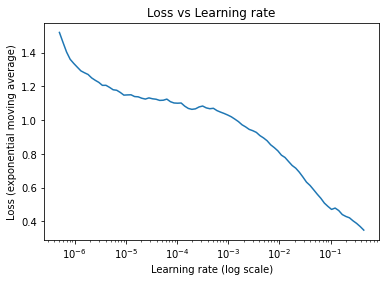

In [ ]:
lrf.plot()

## 2.11. Визуализация результатов обучения

In [ ]:
def plot_training(training_losses,
                  validation_losses,
                  learning_rate,
                  gaussian=True,
                  sigma=2,
                  figsize=(8, 6)
                  ):
    """
    Returns a loss plot with training loss, validation loss and learning rate.
    """

    import matplotlib.pyplot as plt
    from matplotlib import gridspec
    from scipy.ndimage import gaussian_filter

    list_len = len(training_losses)
    x_range = list(range(1, list_len + 1))  # number of x values

    fig = plt.figure(figsize=figsize)
    grid = gridspec.GridSpec(ncols=2, nrows=1, figure=fig)

    subfig1 = fig.add_subplot(grid[0, 0])
    subfig2 = fig.add_subplot(grid[0, 1])

    subfigures = fig.get_axes()

    for i, subfig in enumerate(subfigures, start=1):
        subfig.spines['top'].set_visible(False)
        subfig.spines['right'].set_visible(False)

    if gaussian:
        training_losses_gauss = gaussian_filter(training_losses, sigma=sigma)
        validation_losses_gauss = gaussian_filter(validation_losses, sigma=sigma)

        linestyle_original = '.'
        color_original_train = 'lightcoral'
        color_original_valid = 'lightgreen'
        color_smooth_train = 'red'
        color_smooth_valid = 'green'
        alpha = 0.25
    else:
        linestyle_original = '-'
        color_original_train = 'red'
        color_original_valid = 'green'
        alpha = 1.0

    # Subfig 1
    subfig1.plot(x_range, training_losses, linestyle_original, color=color_original_train, label='Training',
                 alpha=alpha)
    subfig1.plot(x_range, validation_losses, linestyle_original, color=color_original_valid, label='Validation',
                 alpha=alpha)
    if gaussian:
        subfig1.plot(x_range, training_losses_gauss, '-', color=color_smooth_train, label='Training', alpha=0.75)
        subfig1.plot(x_range, validation_losses_gauss, '-', color=color_smooth_valid, label='Validation', alpha=0.75)
    subfig1.title.set_text('Training & validation loss')
    subfig1.set_xlabel('Epoch')
    subfig1.set_ylabel('Loss')

    subfig1.legend(loc='upper right')

    # Subfig 2
    subfig2.plot(x_range, learning_rate, color='black')
    subfig2.title.set_text('Learning rate')
    subfig2.set_xlabel('Epoch')
    subfig2.set_ylabel('LR')

    return fig

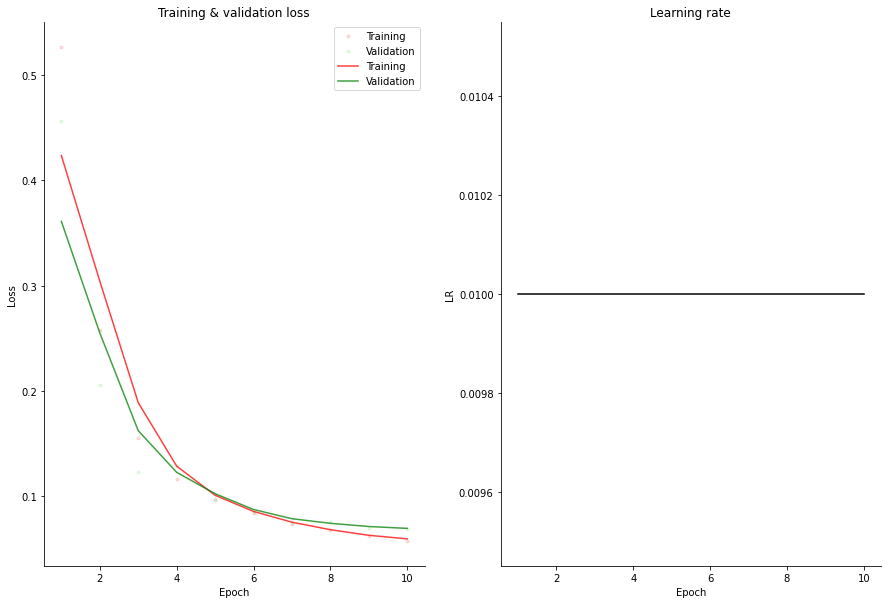

In [ ]:
fig = plot_training(training_losses,
                    validation_losses,
                    lr_rates,
                    gaussian=True,
                    sigma=1,
                    figsize=(15,10))

In [ ]:
# save the model
torch.save(model.state_dict(), "Carvana/carvana_model.pt")

## 2.12. Применение модели

In [ ]:
def predict(img,
            model,
            preprocess,
            postprocess,
            device,
            ):
    model.eval()
    img = preprocess(img)  # preprocess image
    x = torch.from_numpy(img).to(device)  # to torch, send to device
    with torch.no_grad():
        out = model(x)  # send through model/network

    out_softmax = torch.softmax(out, dim=1)  # perform softmax on outputs
    result = postprocess(out_softmax)  # postprocess outputs

    return result

Загрузим модель

In [ ]:
# device
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    torch.device('cpu')

# model
model = UNet(in_channels=3,
             out_channels=2,
             n_blocks=4,
             start_filters=32,
             activation='relu',
             normalization='batch',
             conv_mode='same',
             dim=2).to(device)


model_name = 'carvana_model.pt'
model_weights = torch.load('Carvana/'+model_name)

model.load_state_dict(model_weights)

<All keys matched successfully>

In [ ]:
def get_filenames_of_path(path):
    """Returns a list of files in a directory/path. Uses pathlib."""
    filenames = [filename for filename in os.listdir(path)]
    return filenames

# input and target files
images_names = sorted(get_filenames_of_path('Carvana/Input/'))
targets_names = sorted(get_filenames_of_path('Carvana/Target'))

# read images and store them in memory
images = [imread("Carvana/Input/"+img_name) for img_name in images_names]
targets = [imread("Carvana/Target/"+tar_name) for tar_name in targets_names]

# Resize images and targets
images_res = [resize(img, (128, 128, 3)) for img in images]
resize_kwargs = {'order': 0, 'anti_aliasing': False, 'preserve_range': True}
targets_res = [resize(tar, (128, 128), **resize_kwargs) for tar in targets]

In [ ]:
# preprocess function
def preprocess(img: np.ndarray):
    img = np.moveaxis(img, -1, 0)  # from [H, W, C] to [C, H, W]
    img = normalize_01(img)  # linear scaling to range [0-1]
    img = np.expand_dims(img, axis=0)  # add batch dimension [B, C, H, W]
    img = img.astype(np.float32)  # typecasting to float32
    return img


# postprocess function
def postprocess(img: torch.tensor):
    img = torch.argmax(img, dim=1)  # perform argmax to generate 1 channel
    img = img.cpu().numpy()  # send to cpu and transform to numpy.ndarray
    img = np.squeeze(img)  # remove batch dim and channel dim -> [H, W]
    img = re_normalize(img)  # scale it to the range [0-255]
    return img

In [ ]:
# predict the segmentation maps 
output = [predict(img, model, preprocess, postprocess, device) for img in images_res]

In [ ]:
num_obj = 50

fig, ax = plt.subplots(ncols=2, nrows=num_obj, figsize=(10,num_obj*5))

for i in range(num_obj):
    ax[i,0].imshow(images_res[i])
    ax[i,0].imshow(output[i], cmap="jet", alpha=0.5)
    ax[i,0].axis("off")
    ax[i,0].set_title("Generated")

    ax[i,1].imshow(images_res[i])
    ax[i,1].imshow(targets_res[i], cmap="jet", alpha=0.5)
    ax[i,1].axis("off")
    ax[i,1].set_title("Ground truth")

# 3. Дообучение моделей instance segmentation на примере Mask R-CNN
## 3.0. Подготовительные процедуры

Установка pycocotools

In [ ]:
%%shell

pip install cython
# Install pycocotools, the version by default in Colab
# has a bug fixed in https://github.com/cocodataset/cocoapi/pull/354
pip install -U 'git+https://github.com/cocodataset/cocoapi.git#subdirectory=PythonAPI'

  Cloning https://github.com/cocodataset/cocoapi.git to /tmp/pip-req-build-bfwwwl_5
  Running command git clone -q https://github.com/cocodataset/cocoapi.git /tmp/pip-req-build-bfwwwl_5
  Created wheel for pycocotools: filename=pycocotools-2.0-cp37-cp37m-linux_x86_64.whl size=263919 sha256=30049ea2ccdf8b652b34c867d5d22bc4b4a005e407a48b595f80347aa0616a4d
  Stored in directory: /tmp/pip-ephem-wheel-cache-x9zyzol3/wheels/90/51/41/646daf401c3bc408ff10de34ec76587a9b3ebfac8d21ca5c3a
Successfully built pycocotools
  Found existing installation: pycocotools 2.0.2
    Uninstalling pycocotools-2.0.2:
      Successfully uninstalled pycocotools-2.0.2


Посмотрим несколько картинок из набора данных

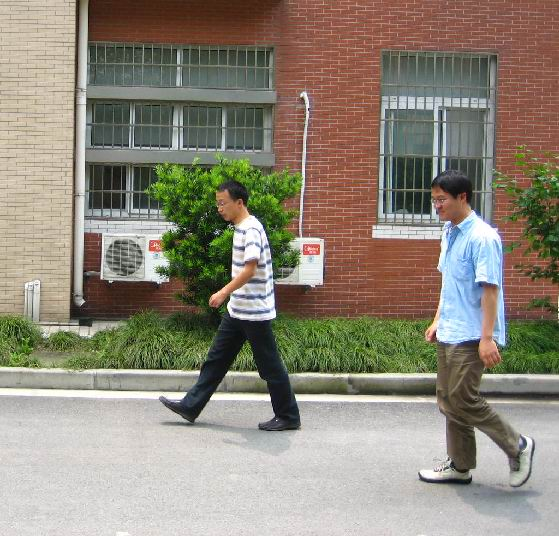

In [ ]:
from PIL import Image
Image.open('PennFudanPed/PNGImages/FudanPed00001.png')

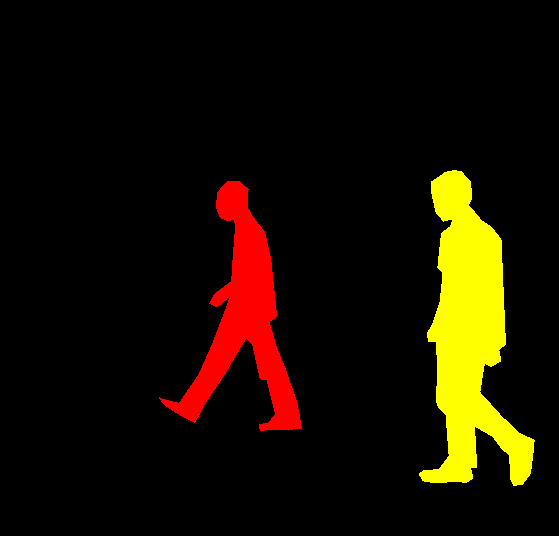

In [ ]:
mask = Image.open('PennFudanPed/PedMasks/FudanPed00001_mask.png')
# each mask instance has a different color, from zero to N, where
# N is the number of instances. In order to make visualization easier,
# let's adda color palette to the mask.
mask.putpalette([
    0, 0, 0, # black background
    255, 0, 0, # index 1 is red
    255, 255, 0, # index 2 is yellow
    255, 153, 0, # index 3 is orange
])
mask

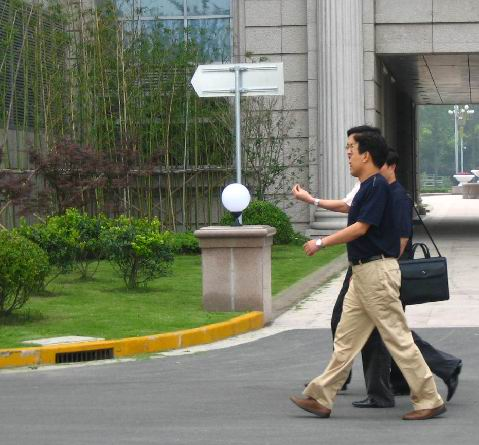

In [ ]:
Image.open('PennFudanPed/PNGImages/FudanPed00003.png')

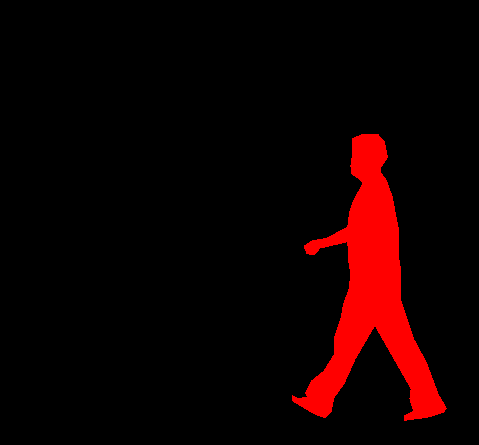

In [ ]:
mask = Image.open('PennFudanPed/PedMasks/FudanPed00003_mask.png')
mask.putpalette([
    0, 0, 0, # black background
    255, 0, 0, # index 1 is red
    255, 255, 0, # index 2 is yellow
    255, 153, 0, # index 3 is orange
])
mask

## 3.1. Создадим класс датасета

In [ ]:
import os
import numpy as np
import torch
from PIL import Image

from engine import train_one_epoch, evaluate
import utils
import transforms as T

In [ ]:
class PennFudanDataset(torch.utils.data.Dataset):
    def __init__(self, root, transforms=None):
        self.root = root
        self.transforms = transforms
        # загрузить все файлы изображений, отсортировав их по
         # убедитесь, что они выровнены
        self.imgs = list(sorted(os.listdir(os.path.join(root, "PNGImages"))))
        self.masks = list(sorted(os.listdir(os.path.join(root, "PedMasks"))))

    def __getitem__(self, idx):
        # load images ad masks
        img_path = os.path.join(self.root, "PNGImages", self.imgs[idx])
        mask_path = os.path.join(self.root, "PedMasks", self.masks[idx])
        img = Image.open(img_path).convert("RGB")
        # обратите внимание, что мы не преобразовали маску в RGB,
         # так как каждый цвет соответствует отдельному экземпляру
         # с 0 в качестве фона
        mask = Image.open(mask_path)

        mask = np.array(mask)
        # экземпляры кодируются разными цветами
        obj_ids = np.unique(mask)
        # первый идентификатор - это фон, поэтому удалите его
        obj_ids = obj_ids[1:]

        # разбиваем маску с цветовой кодировкой на множество
         # бинарных масок
        masks = mask == obj_ids[:, None, None]

        # получаем координаты ограничивающей рамки для каждой маски
        num_objs = len(obj_ids)
        boxes = []
        for i in range(num_objs):
            pos = np.where(masks[i])
            xmin = np.min(pos[1])
            xmax = np.max(pos[1])
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])
            boxes.append([xmin, ymin, xmax, ymax])

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        # есть только один класс
        labels = torch.ones((num_objs,), dtype=torch.int64)
        masks = torch.as_tensor(masks, dtype=torch.uint8)

        image_id = torch.tensor([idx])
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
        # suppose all instances are not crowd
        iscrowd = torch.zeros((num_objs,), dtype=torch.int64)

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["masks"] = masks
        target["image_id"] = image_id
        target["area"] = area
        target["iscrowd"] = iscrowd

        if self.transforms is not None:
            img, target = self.transforms(img, target)

        return img, target

    def __len__(self):
        return len(self.imgs)

In [ ]:
dataset = PennFudanDataset('PennFudanPed/')
dataset[0]

(<PIL.Image.Image image mode=RGB size=559x536 at 0x7FBD3E923D50>,
 {'area': tensor([35358., 36225.]), 'boxes': tensor([[159., 181., 301., 430.],
          [419., 170., 534., 485.]]), 'image_id': tensor([0]), 'iscrowd': tensor([0, 0]), 'labels': tensor([1, 1]), 'masks': tensor([[[0, 0, 0,  ..., 0, 0, 0],
           [0, 0, 0,  ..., 0, 0, 0],
           [0, 0, 0,  ..., 0, 0, 0],
           ...,
           [0, 0, 0,  ..., 0, 0, 0],
           [0, 0, 0,  ..., 0, 0, 0],
           [0, 0, 0,  ..., 0, 0, 0]],
  
          [[0, 0, 0,  ..., 0, 0, 0],
           [0, 0, 0,  ..., 0, 0, 0],
           [0, 0, 0,  ..., 0, 0, 0],
           ...,
           [0, 0, 0,  ..., 0, 0, 0],
           [0, 0, 0,  ..., 0, 0, 0],
           [0, 0, 0,  ..., 0, 0, 0]]], dtype=torch.uint8)})

## 3.2. Определим модель



Mask R-CNN берёт за основу Faster R-CNN и добавляет к ней дополнительную ветвь. Эта ветвь на выходе должна выдать маску объекта в дополнение к ограничивающему прямоугольнику и классу.

Вначале вспомним Faster R-CNN.



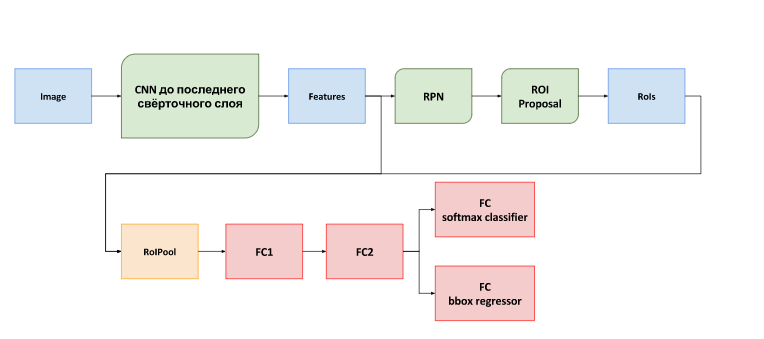

Она состоит из трёх частей:

Генератор особенностей (features extractor), который, получив на вход изображение, выдаёт 3х-мерный тензор особенностей. При этом каждому вектору особенностей из этого тензора соответствует некоторый прямоугольник исходного изображения. В качестве такого генератора может выступать, например, сеть VGG16 или ResNet101 без полносвязных слоёв.

Region Proposal Network (RPN). Сеть, которая получив на вход тензор особенностей, генерирует некоторое количество регионов, в которых предположительно есть объекты

Полносвязные слои - это сеть, которая для каждого региона, вырезает, соответствующую этому региону, часть из тензора особенностей, и выдаёт:

* класс объекта (возможно, что класс будет background)

* уточнённый прямоугольник объекта

Предлагается добавить дополнительную ветвь к полносвязным слоям, которая генерировала бы бинарную маску внутри прямоугольника объекта. Таким образом у сети появляется дополнительный выход, с него для каждого из K классов снимается бинарная маска размера m×m. Соответственно, схема сети меняется следующим образом:

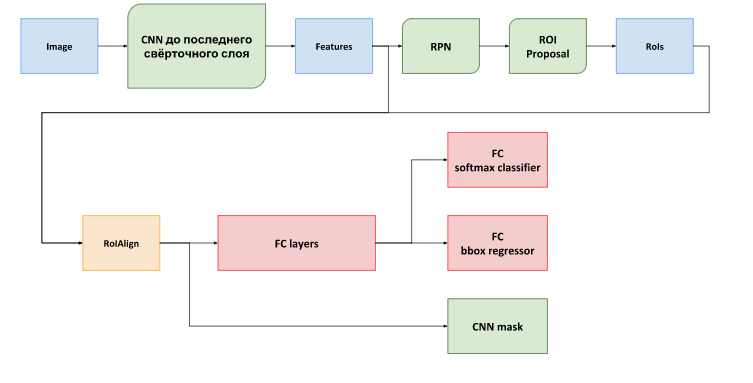

Важно сделать несколько замечаний об отличии Mask R-CNN подхода от случая сегментации изображения.

Во-первых, масок выдаётся K штук, т.е. для каждого класса своя маска, поэтому выбор правильной маски мы осуществляем в зависимости от класса, который выдала сеть. Т.е. в данном подходе разделяется предсказание класса и предсказание маски. Это существенное отличие от случая просто сегментации изображения, например, где на выходе мы имеем для каждого пикселя изображения вектор с вероятностями того, что этот пиксель принадлежит соответствующему классу. Это отличие определяет и вклад маски в функцию ошибки, если ранее это softmax и затем мультиноминальная кросс энтропия, то здесь сигмоид и бинарный штраф.

Во-вторых, сеть генерирует маску фиксированного (не зависящего от размера ROI) размера m×m.

Большая часть Faster R-CNN схемы сохранена (генератор особенностей, RPN, полносвязные слои для получения класса объекта и уточнения прмоугольника). Класс и прямоугольник объекта сеть выдаёт в виде векторов небольшой размерности (для класса это вектор вероятностей, для прямоугольника вектор свигов координат), и их логично генерировать, используя полносвязные слои. Однако, маску, которая по сути бинарное изображение, естественно генерировать, сохраняя пространственную структуру, имеющуюся в тензоре особенностей. А значит вместо полносвязных слоёв будем использовать свёрточные. Это в том числе позволит уменьшить число параметров, а значит упростит обучение.

**RoIAlign**

Еще одно изменение в структуре сети, связанное с желанием получить маску объекта, это замена RoIPool слоя на RoIAlign. В RoIPool для каждого RoI на тензор особенностей накладывалась сетка с фиксированным числом ячеек (например, 7x7) и к каждой ячейке сетки применялся MaxPooling, таким образом для каждого прямоугольника претендента получался тензор особенностей, но уже фиксированных пространственных размерностей (те самые 7x7). Проблема в том, что при извлечении особенностей для прямоугольника при помощи RoIPool процедуры, координаты прямоугольника округляются, а ячейки на которые разбит RoI выравниваются по границам особенностей. В случае когда мы хотим только получить класс объекта и его расположение на изображении, такой “не точный” подход нас вполне устраивает, поскольку данные характеристики объекта устойчивы к малым сдвигам. Однако, для получение маски это упрощение не даёт достаточной точности.

**RoIAlign**

Не округляя координаты и не выравнивая, в каждой ячейке заводим дополнительную сетку. В каждом конкретном случае используются шаблоны билинейной интерполяции, чтобы получить значение особенностей, а затем использовать MaxPool для генерации.  RoIAlign слоя улучшает качество работы сети, как относительно случая RoIPool.

Используем Mask R-CNN, основанный на Faster R-CNN. Faster R-CNN — это модель, которая предсказывает как ограничивающие рамки, так и оценки классов для потенциальных объектов на изображении.

<figure>
<img src="https://pytorch.org/tutorials/_static/img/tv_tutorial/tv_image03.png" width="1000">
</figure> 

Mask R-CNN добавляет дополнительную ветвь в Faster R-CNN, которая также предсказывает маски сегментации для каждого экземпляра.

<figure>
<img src="https://pytorch.org/tutorials/_static/img/tv_tutorial/tv_image04.png" width="1000">
</figure> 


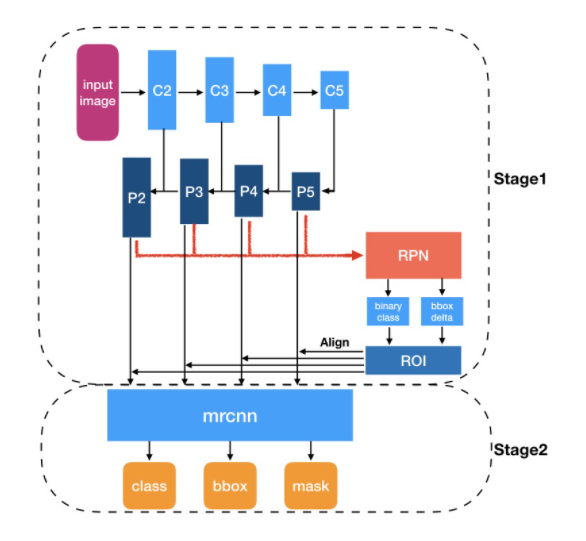

Backbone —  состоит из пути «снизу вверх», пути «сверху вниз» и боковых связей. Восходящим путем может быть любой ConvNet, обычно ResNet или VGG, который извлекает признаки из необработанных изображений. Путь «сверху вниз» создает пирамидальную карту признаков, которая по размеру аналогична пути «снизу вверх». Боковые соединения представляют собой операции свертки и добавления между двумя соответствующими уровнями двух путей.


Облегченная нейронная сеть, называемая RPN, сканирует все пути сверху вниз (далее именуемые картой объектов) и предлагает области, которые могут содержать объекты.


На втором этапе другая нейронная сеть берет предложенные на первом этапе регионы и назначает их нескольким конкретным областям уровня карты объектов, сканирует эти области и генерирует классы объектов (мультикатегориальная классификация), ограничивающие рамки и маски.

Условно разделяют разработанную архитектуру на CNN-сеть вычисления признаков изображения, называемую  backbone, и head — объединение частей, отвечающих за предсказание охватывающей рамки, классификацию объекта и определение его маски. Loss функция для них общая и включает три компонента:
$L = L_{cls} + L_{box} + L_{mask}$


Есть две распространенные ситуации, когда может потребоваться изменить одну из доступных моделей в torchvision modelzoo. Первый — когда мы хотим начать с предварительно обученной модели и просто настроить последний слой. Другой — когда мы хотим заменить основу модели другой (например, для более быстрых прогнозов).

## 3.2.1. Дообучение модели

In [ ]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# загрузить предварительно обученную модель, предварительно обученную на COCO
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)

# replace the classifier with a new one, that has
# num_classes which is user-defined
num_classes = 2  # 1 class (person) + background

# get number of input features for the classifier
in_features = model.roi_heads.box_predictor.cls_score.in_features

# replace the pre-trained head with a new one
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


## 3.2.2. Замена Backbone модели

In [ ]:
import torchvision
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator #Region Proposal Network (RPN)

# загрузить предварительно обученную модель для классификации и возврата
# только features
backbone = torchvision.models.mobilenet_v2(pretrained=True).features

# FasterRCNN needs to know the number of
# output channels in a backbone. For mobilenet_v2, it's 1280
# so we need to add it here
backbone.out_channels = 1280

# let's make the RPN generate 5 x 3 anchors per spatial
# location, with 5 different sizes and 3 different aspect
# ratios. We have a Tuple[Tuple[int]] because each feature
# map could potentially have different sizes and
# aspect ratios
anchor_generator = AnchorGenerator(sizes=((32, 64, 128, 256, 512),),
                                   aspect_ratios=((0.5, 1.0, 2.0),))

# let's define what are the feature maps that we will
# use to perform the region of interest cropping, as well as
# the size of the crop after rescaling.
# if your backbone returns a Tensor, featmap_names is expected to
# be [0]. More generally, the backbone should return an
# OrderedDict[Tensor], and in featmap_names you can choose which
# feature maps to use.
roi_pooler = torchvision.ops.MultiScaleRoIAlign(featmap_names=['0'],
                                                output_size=7,
                                                sampling_ratio=2)

# put the pieces together inside a FasterRCNN model
model = FasterRCNN(backbone,
                   num_classes=2,
                   rpn_anchor_generator=anchor_generator,
                   box_roi_pool=roi_pooler)

Воспользуемся подходом Instance сегментации на основе Mask R-CNN и применим подход дообучения модели

In [ ]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor


def get_model_instance_segmentation(num_classes):
    # загрузить предварительно обученную модель сегментации экземпляра pre-trained на COCO
    model = torchvision.models.detection.maskrcnn_resnet50_fpn(pretrained=True)

    # получить количество входных признаков для классификатора
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # now get the number of input features for the mask classifier
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    # and replace the mask predictor with a new one
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask,
                                                       hidden_layer,
                                                       num_classes)

    return model

## 3.3. Воспользуемся готовыми функциями для обучения и оценки модели

In [ ]:
%%shell

# Download TorchVision repo to use some files from
# references/detection
git clone https://github.com/pytorch/vision.git
cd vision
git checkout v0.3.0

cp references/detection/utils.py ../
cp references/detection/transforms.py ../
cp references/detection/coco_eval.py ../
cp references/detection/engine.py ../
cp references/detection/coco_utils.py ../

Cloning into 'vision'...
remote: Enumerating objects: 21580, done.
remote: Counting objects: 100% (2362/2362), done.
remote: Compressing objects: 100% (537/537), done.
remote: Total 21580 (delta 1830), reused 2244 (delta 1766), pack-reused 19218
Receiving objects: 100% (21580/21580), 21.79 MiB | 9.24 MiB/s, done.
Resolving deltas: 100% (15888/15888), done.
Checking out files: 100% (517/517), done.
error: Your local changes to the following files would be overwritten by checkout:
	.circleci/build_docs/commit_docs.sh
	.circleci/regenerate.py
	.circleci/unittest/ios/scripts/binary_ios_build.sh
	.circleci/unittest/linux/scripts/install.sh
	.circleci/unittest/linux/scripts/post_process.sh
	.circleci/unittest/linux/scripts/run-clang-format.py
	.circleci/unittest/linux/scripts/run_test.sh
	.circleci/unittest/linux/scripts/setup_env.sh
	android/gradlew
	ios/build_ios.sh
	packaging/build_cmake.sh
	packaging/build_conda.sh
	packaging/build_wheel.sh
Please commit your changes or stash them before

Напишем функцию для аугментации данных

In [ ]:
def get_transform(train):
    transforms = []
    # converts the image, a PIL image, into a PyTorch Tensor
    transforms.append(T.ToTensor())
    if train:
        # during training, randomly flip the training images
        # and ground-truth for data augmentation
        transforms.append(T.RandomHorizontalFlip(0.5))
    return T.Compose(transforms)

## 3.4. Инициализация и обучение модели

In [ ]:
# use our dataset and defined transformations
dataset = PennFudanDataset('PennFudanPed', get_transform(train=True))
dataset_test = PennFudanDataset('PennFudanPed', get_transform(train=False))

# split the dataset in train and test set
torch.manual_seed(1)
indices = torch.randperm(len(dataset)).tolist()
dataset = torch.utils.data.Subset(dataset, indices[:-50])
dataset_test = torch.utils.data.Subset(dataset_test, indices[-50:])

# define training and validation data loaders
data_loader = torch.utils.data.DataLoader(
    dataset, batch_size=2, shuffle=True, num_workers=4,
    collate_fn=utils.collate_fn)

data_loader_test = torch.utils.data.DataLoader(
    dataset_test, batch_size=1, shuffle=False, num_workers=4,
    collate_fn=utils.collate_fn)

/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:477: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


In [ ]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# our dataset has two classes only - background and person
num_classes = 2

# get the model using our helper function
model = get_model_instance_segmentation(num_classes)
# move model to the right device
model.to(device)

# construct an optimizer
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005,
                            momentum=0.9, weight_decay=0.0005)

# and a learning rate scheduler which decreases the learning rate by
# 10x every 3 epochs
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                               step_size=3,
                                               gamma=0.1)

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


In [ ]:
# let's train it for 10 epochs
num_epochs = 10

for epoch in range(num_epochs):
    # train for one epoch, printing every 10 iterations
    train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq=10)
    # update the learning rate
    lr_scheduler.step()
    # evaluate on the test dataset
    evaluate(model, data_loader_test, device=device)

/usr/local/lib/python3.7/dist-packages/torch/utils/data/dataloader.py:477: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  cpuset_checked))


Epoch: [0]  [ 0/60]  eta: 0:01:03  lr: 0.000090  loss: 5.6199 (5.6199)  loss_classifier: 0.9516 (0.9516)  loss_box_reg: 0.2613 (0.2613)  loss_mask: 4.3808 (4.3808)  loss_objectness: 0.0231 (0.0231)  loss_rpn_box_reg: 0.0031 (0.0031)  time: 1.0643  data: 0.4707  max mem: 3573
Epoch: [0]  [10/60]  eta: 0:00:28  lr: 0.000936  loss: 1.8971 (2.8710)  loss_classifier: 0.5845 (0.5518)  loss_box_reg: 0.1971 (0.2263)  loss_mask: 1.1158 (2.0546)  loss_objectness: 0.0231 (0.0317)  loss_rpn_box_reg: 0.0037 (0.0066)  time: 0.5760  data: 0.0476  max mem: 3573
Epoch: [0]  [20/60]  eta: 0:00:22  lr: 0.001783  loss: 1.1210 (1.8998)  loss_classifier: 0.2237 (0.3819)  loss_box_reg: 0.1971 (0.2314)  loss_mask: 0.4518 (1.2489)  loss_objectness: 0.0214 (0.0283)  loss_rpn_box_reg: 0.0073 (0.0092)  time: 0.5419  data: 0.0069  max mem: 3573
Epoch: [0]  [30/60]  eta: 0:00:16  lr: 0.002629  loss: 0.6695 (1.4706)  loss_classifier: 0.1185 (0.2880)  loss_box_reg: 0.1949 (0.2150)  loss_mask: 0.3021 (0.9329)  loss_ob

In [ ]:
# save the model
torch.save(model.state_dict(), "fundan_mask_rcnn.pt")

## 3.5. Визуализация результатов работы модели

In [ ]:
# pick one image from the test set
img, _ = dataset_test[1]
# put the model in evaluation mode
model.eval()
with torch.no_grad():
    prediction = model([img.to(device)])

In [ ]:
prediction

[{'boxes': tensor([[ 91.0353,  64.5199, 234.9442, 341.7801],
          [247.6675,  62.8699, 305.5940, 348.1744],
          [247.5428,  28.5257, 359.4350, 363.0674],
          [140.2834,  52.6361, 321.8383, 347.1274]], device='cuda:0'),
  'labels': tensor([1, 1, 1, 1], device='cuda:0'),
  'masks': tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            ...,
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.]]],
  
  
          [[[0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            ...,
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.]]],
  
  
          [[[0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0.,

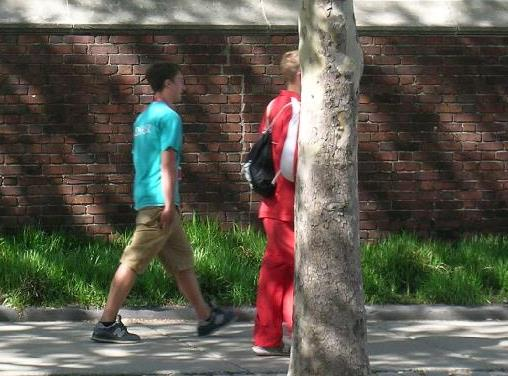

In [ ]:
Image.fromarray(img.mul(255).permute(1, 2, 0).byte().numpy())

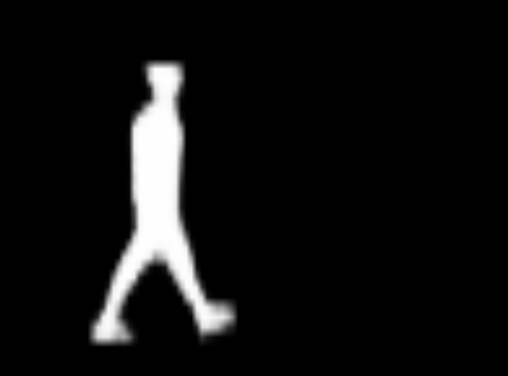

In [ ]:
Image.fromarray(prediction[0]['masks'][0, 0].mul(255).byte().cpu().numpy())

# 4. Задание:


Для Модели Mask R-CNN реализовать пайплайн визуализацию, в результате применения которого на исходном изображении будут отображены bounding box-ы и показыны границы каждого объекта. Пример представлен ниже:
<figure>
<img src="https://pytorch.org/tutorials/_static/img/tv_tutorial/tv_image01.png" width="1000">
</figure> 

# 5. Использованные материалы:
- https://pytorch.org/tutorials/beginner/finetuning_torchvision_models_tutorial.html
- https://towardsdatascience.com/creating-and-training-a-u-net-model-with-pytorch-for-2d-3d-semantic-segmentation-dataset-fb1f7f80fe55
- https://pytorch.org/tutorials/intermediate/torchvision_tutorial.html